In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
path = '../data/processed/merged_cleaned_2019.csv'

cols_needed = ['club_member_status','product_group_name','price']

df = pd.read_csv(path,usecols=cols_needed)


In [ ]:
df['club_member_status'].value_counts()

club_member_status
ACTIVE        15997833
PRE-CREATE      363620
Unknown          30007
LEFT CLUB         5470
Name: count, dtype: int64

In [ ]:

price_stats = (df.groupby('club_member_status')['price'].agg(['count', 'mean', 'median', 'std'])
)

price_stats['mean_vs_active_pct'] = (price_stats['mean'] / price_stats.loc['ACTIVE', 'mean'] - 1) * 100

price_stats['mean_vs_median_pct'] = (price_stats['mean'] / price_stats['median'] - 1) * 100
price_stats.round(4)


,count,mean,median,std,mean_vs_active_pct,mean_vs_median_pct
club_member_status,,,,,,
ACTIVE,15997833,0.0277,0.0254,0.0193,0.0000,9.1247
LEFT CLUB,5470,0.0295,0.0254,0.0221,6.3341,16.0368
PRE-CREATE,363620,0.0303,0.0254,0.0203,9.2019,19.1663
Unknown,30007,0.0298,0.0254,0.0215,7.3970,17.1967


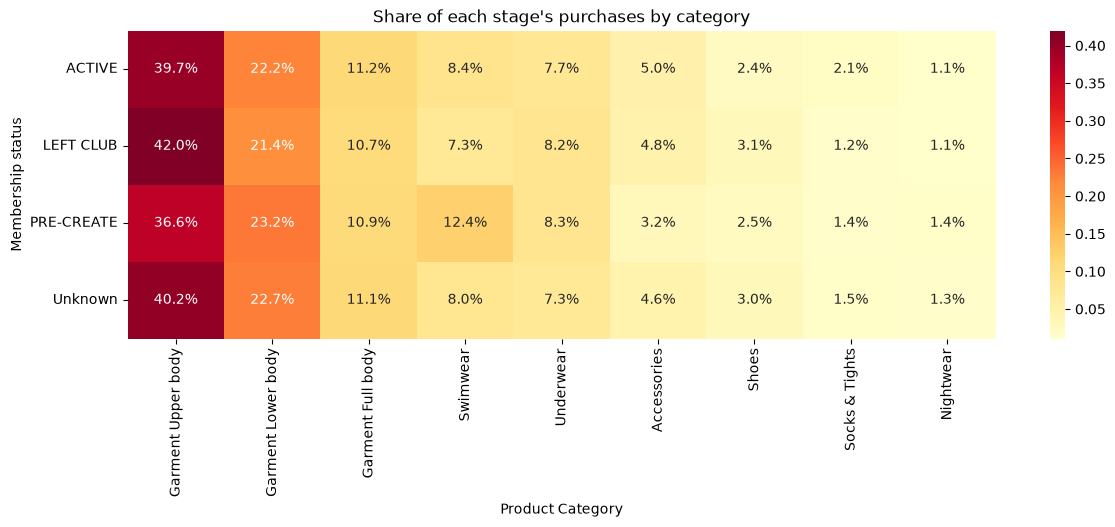

In [27]:
status_group = pd.crosstab(df['club_member_status'], df['product_group_name'])

membership_share = status_group.div(status_group.sum(axis=1), axis=0)   

overall_share = status_group.sum() / status_group.sum().sum()  
         
major_category = overall_share[overall_share >= 0.01].sort_values(ascending=False).index

plt.figure(figsize=(14, 4))

sns.heatmap(
  membership_share[major_category], cmap='YlOrRd', 
  annot=True, 
  fmt='.1%')

plt.title("Share of each stage's purchases by category")

plt.xlabel('Product Category')
plt.ylabel('Membership status')

plt.show()

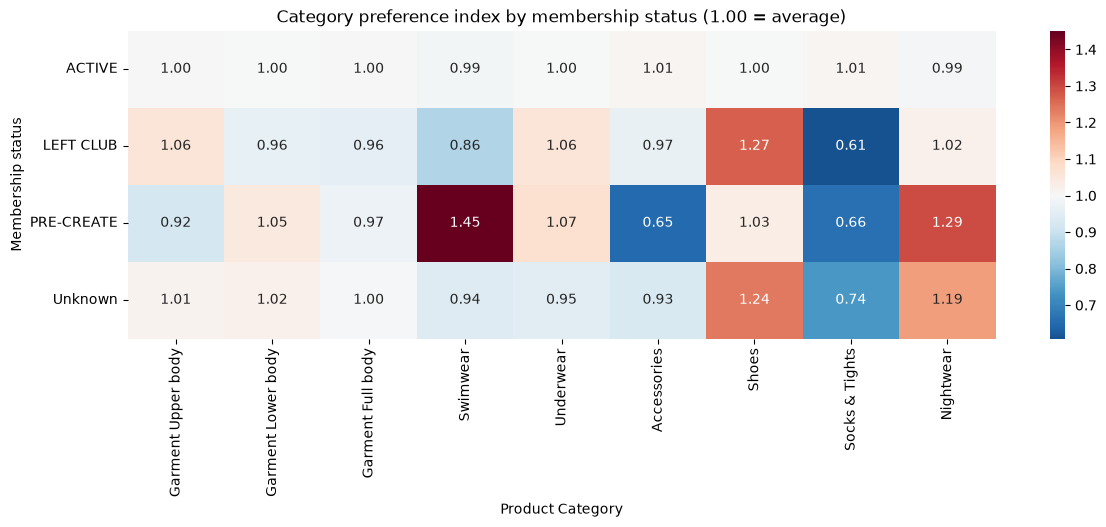

In [28]:
preference_index = membership_share.div(overall_share, axis=1)

plt.figure(figsize=(14, 4))

sns.heatmap(preference_index[major_category], cmap='RdBu_r', center=1, annot=True, fmt='.2f')
plt.title('Category preference index by membership status (1.00 = average)')

plt.xlabel('Product Category')
plt.ylabel('Membership status')

plt.savefig('../reports/membership_preference_index.png', dpi=150, bbox_inches='tight')

plt.show()

In [29]:
summary = pd.DataFrame({
    'purchases':status_group.sum(axis=1),
    'most_over_indexed': preference_index[major_category].idxmax(axis=1),
    'index_high':preference_index[major_category].max(axis=1).round(2),
    'most_under_indexed': preference_index[major_category].idxmin(axis=1),
    'index_low': preference_index[major_category].min(axis=1).round(2),
})
summary

,purchases,most_over_indexed,index_high,most_under_indexed,index_low
club_member_status,,,,,
ACTIVE,15997833,Socks & Tights,1.01,Swimwear,0.99
LEFT CLUB,5470,Shoes,1.27,Socks & Tights,0.61
PRE-CREATE,363620,Swimwear,1.45,Accessories,0.65
Unknown,30007,Shoes,1.24,Socks & Tights,0.74


## Findings

ACTIVE accounts for about 97.6% of purchases, PRE-CREATE for about 2.2%, and Unknown and LEFT CLUB for under 0.2% each. Raw totals only reflect group size, so I compared shares and per-purchase measures.

The median price is identical in all four groups, 0.025407, so the typical purchase costs the same whatever the status. The mean is 6 to 9% higher in the three smaller groups than in ACTIVE, which is consistent with a few more expensive purchases and not with a shift in the typical price.

ACTIVE buys almost exactly the average category mix, with indexes of 0.99 to 1.01. PRE-CREATE over-buys Swimwear, with an index of 1.45. LEFT CLUB and Unknown over-buy Shoes at 1.27 and 1.24, and under-buy Socks & Tights. That is consistent with their higher means, since Shoes cost more than Socks & Tights.

LEFT CLUB has only 5,470 purchases, so its results are the least reliable. The status is a customer attribute and not necessarily the status at purchase time.